Seed set to 0
[09:14:37] Explicit valence for atom # 2 S, 6, is greater than permitted


Generated 19137 usable Joback pseudo-labels out of 20000 attempted
Loaded 19137 rows, dropped 0 with missing/invalid target, smiles, or stereo issues, 19137 remain


The return type of make_split_indices has changed in v2.1 - see help(make_split_indices)
c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\astartes\samplers\extrapolation\scaffold.py:48: NoMatchingScaffold: No matching scaffold was found for the 461 molecules corresponding to indices {4097, 12289, 12311, 16408, 27, 6180, 2088, 43, 14381, 8240, 18481, 2099, 8250, 16447, 68, 72, 14408, 14414, 18534, 18547, 16513, 10370, 6279, 137, 138, 14478, 14479, 152, 6297, 16539, 6302, 18592, 161, 14499, 2217, 8368, 16568, 191, 4291, 10435, 16579, 8392, 10445, 206, 18642, 6359, 216, 12510, 2276, 6374, 18663, 8425, 2284, 237, 6387, 14583, 4346, 18687, 12544, 18692, 4359, 4366, 6414, 16656, 10515, 4372, 6421, 4378, 10533, 4390, 10534, 2351, 14647, 10558, 8511, 10559, 8523, 2381, 8533, 8536, 16728, 2400, 14688, 12645, 18805, 14717, 12676, 390, 6536, 400, 2455, 410, 18842, 6559, 416, 423, 4523, 6572, 8619, 18864, 10674, 449, 14801, 14808, 2522, 8670, 18918, 4584, 10729, 1892

scaffold_balanced: train=15311, val=1913, test=1913


c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


┏━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name            ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ message_passing │ BondMessagePassing │  227 K │ train │     0 │
│ 1 │ agg             │ MeanAggregation    │      0 │ train │     0 │
│ 2 │ bn              │ BatchNorm1d        │    600 │ train │     0 │
│ 3 │ predictor       │ RegressionFFN      │ 90.6 K │ train │     0 │
│ 4 │ X_d_transform   │ Identity           │      0 │ train │     0 │
│ 5 │ metrics         │ ModuleList         │      0 │ train │     0 │
└───┴─────────────────┴────────────────────┴────────┴───────┴───────┘

... (19 outputs left out)

Output()

Hybrid model (fine-tuned) — RMSE: 2.090, MAE: 1.618


c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Straight Joback — RMSE: 3.253, MAE: 2.244 (n=438/465 — some molecules have unassignable groups)
                                  Model      MAE     RMSE
                        Straight Joback 2.244011 3.252774
                 Baseline (random init) 1.464109 2.014384
Hybrid (Joback-pretrained + fine-tuned) 1.618379 2.090027


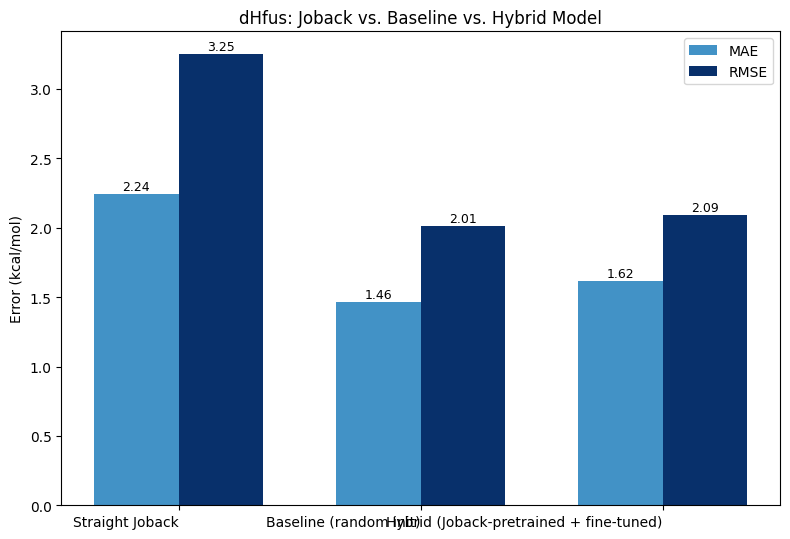

In [1]:
#THIS NOTEBOOK IMPLEMENTS THE JOBACK-HYBRIDIZATION APPROACH: PRETRAIN A D-MPNN ON JOBACK'S PREDICTIONS
#(FREE, STRUCTURE-ONLY LABELS), THEN FINE-TUNE THAT PRETRAINED MODEL ON REAL EXPERIMENTAL dHfus DATA.
#COMPARES: STRAIGHT JOBACK vs. BASELINE (RANDOM INIT) vs. HYBRID (JOBACK-PRETRAINED + FINE-TUNED)

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lightning import pytorch as pl

from chemprop_utils import (
    load_and_clean_data, build_splits, build_and_train_mpnn, build_and_finetune_mpnn,
    predict_test_set, joback_predict_dHfus,
)

pl.seed_everything(0, workers=True)


# 1. LOAD LOCKED dHfus BASELINE'S SPLIT (SAME MOLECULES, SAME TRAIN/VAL/TEST, FOR FAIR COMPARISON)

import pickle
with open("dHfus_baseline_splits.pkl", "rb") as f:
    splits = pickle.load(f)
dhfus_baseline_predictions = pd.read_csv("dHfus_baseline_predictions.csv")


# 2. GENERATE JOBACK PSEUDO-LABELS ON A LARGE MOLECULE POOL (REUSING CLEANED Tm SMILES — FREE, NO REAL LABELS NEEDED)

tm_pool = pd.read_csv("RAW DATA/Tmp_DB.csv")["smiles"].dropna().sample(n=20000, random_state=0).tolist()

pretrain_records = []
for smi in tm_pool:
    pred = joback_predict_dHfus(smi)
    if pred is not None and pred > 0:   #FILTERS OUT FAILED/UNASSIGNABLE/NONSENSICAL PREDICTIONS
        pretrain_records.append({"smiles": smi, "dHfus_joback": pred})

df_pretrain = pd.DataFrame(pretrain_records)
print(f"Generated {len(df_pretrain)} usable Joback pseudo-labels out of {len(tm_pool)} attempted")
df_pretrain.to_csv("RAW DATA/dHfus_joback_pretrain.csv", index=False)

# 3. PRETRAIN THE MPNN ON JOBACK'S PSEUDO-LABELS

df_pt, all_data_pt, mols_pt = load_and_clean_data(
    Path("RAW DATA") / "dHfus_joback_pretrain.csv", "smiles", ["dHfus_joback"]
)
splits_pt = build_splits(all_data_pt, mols_pt, split_types=("scaffold_balanced",))

result_pretrain = build_and_train_mpnn(
    splits_pt["scaffold_balanced"]["train"], splits_pt["scaffold_balanced"]["val"], splits_pt["scaffold_balanced"]["test"],
    dropout=0.4, run_name="dHfus_joback_pretrain",
)
pretrain_test = result_pretrain["test_results"][0]
print(f"Pretraining (vs Joback pseudo-labels) — RMSE: {pretrain_test['test/rmse']:.3f}, MAE: {pretrain_test['test/mae']:.3f}")
print("Pretrain checkpoint:", result_pretrain["best_ckpt_path"])


# 4. FINE-TUNE THE PRETRAINED MODEL ON REAL dHfus DATA (SAME SPLIT AS YOUR BASELINE)

result_hybrid = build_and_finetune_mpnn(
    pretrained_ckpt_path=result_pretrain["best_ckpt_path"],
    train_data=splits["scaffold_balanced"]["train"], val_data=splits["scaffold_balanced"]["val"], test_data=splits["scaffold_balanced"]["test"],
    dropout=0.4, run_name="dHfus_hybrid_finetuned",
)
hybrid_test = result_hybrid["test_results"][0]
print(f"Hybrid model (fine-tuned) — RMSE: {hybrid_test['test/rmse']:.3f}, MAE: {hybrid_test['test/mae']:.3f}")

hybrid_predictions = predict_test_set(result_hybrid, run_name="dHfus_hybrid")
hybrid_predictions.to_csv("dHfus_hybrid_predictions.csv", index=False)


# 5. STRAIGHT JOBACK ON THE SAME TEST-SET MOLECULES (NO TRAINING — DIRECT FORMULA)

joback_preds = dhfus_baseline_predictions["smiles"].apply(joback_predict_dHfus)
joback_valid = joback_preds.notna()

joback_mae = np.abs(joback_preds[joback_valid] - dhfus_baseline_predictions.loc[joback_valid, "y_true"]).mean()
joback_rmse = np.sqrt(((joback_preds[joback_valid] - dhfus_baseline_predictions.loc[joback_valid, "y_true"]) ** 2).mean())
print(f"Straight Joback — RMSE: {joback_rmse:.3f}, MAE: {joback_mae:.3f} "
      f"(n={joback_valid.sum()}/{len(dhfus_baseline_predictions)} — some molecules have unassignable groups)")


# 6. FINAL THREE-WAY COMPARISON TABLE + BAR CHART

final_comparison = pd.DataFrame({
    "Model": ["Straight Joback", "Baseline (random init)", "Hybrid (Joback-pretrained + fine-tuned)"],
    "MAE": [joback_mae, dhfus_baseline_predictions["abs_error"].mean(), hybrid_test["test/mae"]],
    "RMSE": [joback_rmse, np.sqrt((dhfus_baseline_predictions["abs_error"] ** 2).mean()), hybrid_test["test/rmse"]],
})
print(final_comparison.to_string(index=False))
final_comparison.to_csv("dHfus_hybridization_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
x = np.arange(len(final_comparison))
width = 0.35
bars_mae = ax.bar(x - width/2, final_comparison["MAE"], width, label="MAE", color="#4292c6")
bars_rmse = ax.bar(x + width/2, final_comparison["RMSE"], width, label="RMSE", color="#08306b")
for bars in [bars_mae, bars_rmse]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f"{height:.2f}", xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(final_comparison["Model"], rotation=0, ha="right")
ax.set_ylabel("Error (kcal/mol)")
ax.set_title("dHfus: Joback vs. Baseline vs. Hybrid Model")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_hybridization_comparison.png", dpi=150)
plt.show()




In [2]:
print(f"Pretrain test — RMSE: {pretrain_test['test/rmse']:.3f}, MAE: {pretrain_test['test/mae']:.3f}")

Pretrain test — RMSE: 1.593, MAE: 1.068
